# Security Attack Detection Using Artificial Neural Network and Random Forest


## Mini Project

This project reproduces the Artificial Neural Network (ANN) approach described in the reference paper for security attack detection using the NSL-KDD dataset.

An additional Random Forest model is implemented to extend the reference work and compare its performance with the original ANN model.

### Models
- Reference Model: Artificial Neural Network (ANN)
- Additional Model: Random Forest

### Dataset
NSL-KDD

### Team

| Name | SRN |
|---|---|
| Samaresh | PES2UG24CS657 |
| B S SHARATH CHANDRA REDDY | PES2UG24CS630 |

## Project Objectives

1. Reproduce the results of the reference ANN model using the NSL-KDD dataset.
2. Follow the preprocessing and ANN architecture described in the reference.
3. Evaluate the reproduced model using accuracy, precision, recall, and F1-score.
4. Extend the work by implementing a Random Forest classifier.
5. Compare the ANN and Random Forest using the same test dataset and evaluation metrics.

In [47]:
import sys
import pandas as pd
import numpy as np
import sklearn

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: p:\job\ml mini\ML_MINI_PROJ\venv\Scripts\python.exe
Pandas: 3.0.6
NumPy: 2.5.3
Scikit-learn: 1.9.1


In [48]:
import pandas as pd

# Column names from the NSL-KDD dataset
columns = [
    "duration",
    "protocol_type",
    "service",
    "flag",
    "src_bytes",
    "dst_bytes",
    "land",
    "wrong_fragment",
    "urgent",
    "hot",
    "num_failed_logins",
    "logged_in",
    "num_compromised",
    "root_shell",
    "su_attempted",
    "num_root",
    "num_file_creations",
    "num_shells",
    "num_access_files",
    "num_outbound_cmds",
    "is_host_login",
    "is_guest_login",
    "count",
    "srv_count",
    "serror_rate",
    "srv_serror_rate",
    "rerror_rate",
    "srv_rerror_rate",
    "same_srv_rate",
    "diff_srv_rate",
    "srv_diff_host_rate",
    "dst_host_count",
    "dst_host_srv_count",
    "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate",
    "dst_host_srv_serror_rate",
    "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate",
    "attack_type",
    "difficulty"
]

# Load training and testing data
train_df = pd.read_csv(
    "data/KDDTrain+.txt",
    header=None,
    names=columns
)

test_df = pd.read_csv(
    "data/KDDTest+.txt",
    header=None,
    names=columns
)

print("Training shape:", train_df.shape)
print("Testing shape :", test_df.shape)

Training shape: (125973, 43)
Testing shape : (22544, 43)


In [49]:
print("Number of features:", len(columns) - 2)

print("\nFirst 5 rows:")
display(train_df.head())

display(train_df["attack_type"].value_counts())

Number of features: 41

First 5 rows:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack_type,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


attack_type
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64

In [50]:
# Separate input features and target

feature_columns = columns[:41]

X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

y_train = train_df["attack_type"].copy()
y_test = test_df["attack_type"].copy()

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\nCategorical columns:")
print(X_train.select_dtypes(include="object").columns.tolist())

X_train: (125973, 41)
X_test : (22544, 41)

Categorical columns:
['protocol_type', 'service', 'flag']


C:\Users\Shammu\AppData\Local\Temp\ipykernel_30256\301036780.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X_train.select_dtypes(include="object").columns.tolist())


In [51]:
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "protocol_type",
    "service",
    "flag"
]

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_cat = encoder.fit_transform(
    X_train[categorical_features]
)

X_test_cat = encoder.transform(
    X_test[categorical_features]
)

print("Encoded categorical training shape:", X_train_cat.shape)
print("Encoded categorical testing shape :", X_test_cat.shape)

Encoded categorical training shape: (125973, 84)
Encoded categorical testing shape : (22544, 84)


In [52]:
import numpy as np

numerical_features = [
    col for col in feature_columns
    if col not in categorical_features
]

X_train_num = X_train[numerical_features].to_numpy()
X_test_num = X_test[numerical_features].to_numpy()

X_train_processed = np.hstack([
    X_train_num,
    X_train_cat
])

X_test_processed = np.hstack([
    X_test_num,
    X_test_cat
])

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape :", X_test_processed.shape)

Processed training shape: (125973, 122)
Processed testing shape : (22544, 122)


In [53]:
# Scale the features using StandardScaler

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_processed)

X_test_scaled = scaler.transform(X_test_processed)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape :", X_test_scaled.shape)

Scaled training shape: (125973, 122)
Scaled testing shape : (22544, 122)


In [54]:
print("Mean of scaled training data:")
print(np.mean(X_train_scaled))

print("\nStandard deviation of scaled training data:")
print(np.std(X_train_scaled))

Mean of scaled training data:
-2.5179353385190656e-15

Standard deviation of scaled training data:
0.9958932064677569


In [55]:
# Encode the target labels using LabelEncoder(attack names to numbers)
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)

# Use the same encoder for test labels
# Unknown test attack types will be handled separately later.
known_test_mask = y_test.isin(label_encoder.classes_)

y_test_known = y_test[known_test_mask]
y_test_encoded = label_encoder.transform(y_test_known)

print("Number of training classes:", len(label_encoder.classes_))
print("\nTraining classes:")
print(label_encoder.classes_)

Number of training classes: 23

Training classes:
['back' 'buffer_overflow' 'ftp_write' 'guess_passwd' 'imap' 'ipsweep'
 'land' 'loadmodule' 'multihop' 'neptune' 'nmap' 'normal' 'perl' 'phf'
 'pod' 'portsweep' 'rootkit' 'satan' 'smurf' 'spy' 'teardrop'
 'warezclient' 'warezmaster']


In [56]:
print("Number of classes:", len(label_encoder.classes_))

print("\nEncoded training label shape:")
print(y_train_encoded.shape)

print("\nTest records with known training labels:")
print(len(y_test_known))

print("\nTest records with unseen labels:")
print(len(y_test) - len(y_test_known))

Number of classes: 23

Encoded training label shape:
(125973,)

Test records with known training labels:
18794

Test records with unseen labels:
3750


In [57]:
# Find attack types in the test set that are not present in training

training_classes = set(y_train.unique())
test_classes = set(y_test.unique())

unseen_attacks = sorted(test_classes - training_classes)

print("Unseen attack types:")
print(unseen_attacks)

print("\nNumber of unseen attack types:", len(unseen_attacks))

print("\nCounts of unseen attacks:")
print(
    y_test[y_test.isin(unseen_attacks)].value_counts()
)

Unseen attack types:
['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']

Number of unseen attack types: 17

Counts of unseen attacks:
attack_type
mscan            996
apache2          737
processtable     685
snmpguess        331
saint            319
mailbomb         293
snmpgetattack    178
httptunnel       133
named             17
ps                15
sendmail          14
xterm             13
xlock              9
xsnoop             4
worm               2
sqlattack          2
udpstorm           2
Name: count, dtype: int64


In [58]:
# Map every NSL-KDD attack type to the 5 broad categories

dos_attacks = {
    "back", "land", "neptune", "pod", "smurf", "teardrop",
    "apache2", "mailbomb", "processtable", "udpstorm", "worm"
}

probe_attacks = {
    "ipsweep", "nmap", "portsweep", "satan",
    "mscan", "saint"
}

r2l_attacks = {
    "ftp_write", "guess_passwd", "imap", "multihop",
    "phf", "warezclient", "warezmaster",
    "httptunnel", "named", "sendmail", "snmpgetattack",
    "snmpguess", "xlock", "xsnoop"
}

u2r_attacks = {
    "buffer_overflow", "loadmodule", "perl",
    "rootkit", "spy", "ps", "sqlattack", "xterm"
}


def attack_category(attack):
    if attack == "normal":
        return "Normal"
    elif attack in dos_attacks:
        return "DoS"
    elif attack in probe_attacks:
        return "Probe"
    elif attack in r2l_attacks:
        return "R2L"
    elif attack in u2r_attacks:
        return "U2R"
    else:
        return "Unknown"


train_df["attack_category"] = train_df["attack_type"].apply(attack_category)
test_df["attack_category"] = test_df["attack_type"].apply(attack_category)

print("Training categories:")
print(train_df["attack_category"].value_counts())

print("\nTesting categories:")
print(test_df["attack_category"].value_counts())

print("\nUnknown training attacks:")
print(train_df[train_df["attack_category"] == "Unknown"]["attack_type"].unique())

print("\nUnknown testing attacks:")
print(test_df[test_df["attack_category"] == "Unknown"]["attack_type"].unique())

Training categories:
attack_category
Normal    67343
DoS       45927
Probe     11656
R2L         993
U2R          54
Name: count, dtype: int64

Testing categories:
attack_category
Normal    9711
DoS       7460
R2L       2885
Probe     2421
U2R         67
Name: count, dtype: int64

Unknown training attacks:
<StringArray>
[]
Length: 0, dtype: str

Unknown testing attacks:
<StringArray>
[]
Length: 0, dtype: str


In [59]:
# Exact attack classes present in the training set

training_attack_classes = sorted(
    train_df["attack_type"].unique()
)

print("Number of training attack classes:", len(training_attack_classes))

for i, attack in enumerate(training_attack_classes):
    print(f"{i:2d} -> {attack}")

Number of training attack classes: 23
 0 -> back
 1 -> buffer_overflow
 2 -> ftp_write
 3 -> guess_passwd
 4 -> imap
 5 -> ipsweep
 6 -> land
 7 -> loadmodule
 8 -> multihop
 9 -> neptune
10 -> nmap
11 -> normal
12 -> perl
13 -> phf
14 -> pod
15 -> portsweep
16 -> rootkit
17 -> satan
18 -> smurf
19 -> spy
20 -> teardrop
21 -> warezclient
22 -> warezmaster


In [60]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

In [61]:

# Encode the 23 attack classes
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(
    train_df["attack_type"]
)

# Convert integer labels to one-hot vectors
y_train_onehot = to_categorical(
    y_train_encoded,
    num_classes=len(label_encoder.classes_)
)

print("Number of classes:", len(label_encoder.classes_))
print("Integer labels shape:", y_train_encoded.shape)
print("One-hot labels shape:", y_train_onehot.shape)

Number of classes: 23
Integer labels shape: (125973,)
One-hot labels shape: (125973, 23)


In [62]:
print("Classes:")
for i, label in enumerate(label_encoder.classes_):
    print(i, "->", label)

print("\nExample integer labels:")
print(y_train_encoded[:10])

print("\nExample one-hot label:")
print(y_train_onehot[0])

Classes:
0 -> back
1 -> buffer_overflow
2 -> ftp_write
3 -> guess_passwd
4 -> imap
5 -> ipsweep
6 -> land
7 -> loadmodule
8 -> multihop
9 -> neptune
10 -> nmap
11 -> normal
12 -> perl
13 -> phf
14 -> pod
15 -> portsweep
16 -> rootkit
17 -> satan
18 -> smurf
19 -> spy
20 -> teardrop
21 -> warezclient
22 -> warezmaster

Example integer labels:
[11 11  9 11 11  9  9  9  9  9]

Example one-hot label:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## Target Label Encoding

The NSL-KDD dataset contains individual attack types as labels. The reference paper represents the target variable `Y` using **24 output columns**.

These 24 columns consist of:

- **1 column** for normal system behaviour
- **22 columns** for the known attack types present in the training dataset
- **1 additional column** for any unknown attack

The additional `unknown` class is important because the NSL-KDD test dataset contains **17 attack types that do not appear in the training dataset**. These attacks cannot be represented as individual classes learned during training, so the reference paper assigns them to the final `unknown` output column.

Therefore:

**23 known classes + 1 unknown class = 24 output classes**

The neural network will use these 24 classes as its output layer.

In [63]:
# Create the 24 output classes used by the reference paper

known_classes = list(label_encoder.classes_)

UNKNOWN_CLASS = "unknown"

output_classes = known_classes + [UNKNOWN_CLASS]

print("Total output classes:", len(output_classes))

for i, label in enumerate(output_classes):
    print(f"{i:2d} -> {label}")

Total output classes: 24
 0 -> back
 1 -> buffer_overflow
 2 -> ftp_write
 3 -> guess_passwd
 4 -> imap
 5 -> ipsweep
 6 -> land
 7 -> loadmodule
 8 -> multihop
 9 -> neptune
10 -> nmap
11 -> normal
12 -> perl
13 -> phf
14 -> pod
15 -> portsweep
16 -> rootkit
17 -> satan
18 -> smurf
19 -> spy
20 -> teardrop
21 -> warezclient
22 -> warezmaster
23 -> unknown


In [64]:
# Create 24-dimensional one-hot training labels

y_train_24 = to_categorical(
    y_train_encoded,
    num_classes=24
)

print("Training label shape:", y_train_24.shape)

print("\nFirst training label:")
print(y_train_24[0])

print("\nSum of first label:")
print(y_train_24[0].sum())

Training label shape: (125973, 24)

First training label:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Sum of first label:
1.0


In [65]:
# Create 24-class test labels
# Unknown attacks are assigned to the final class (index 23)

known_class_to_index = {
    class_name: index
    for index, class_name in enumerate(known_classes)
}

y_test_24_indices = []

for attack in y_test:
    if attack in known_class_to_index:
        y_test_24_indices.append(
            known_class_to_index[attack]
        )
    else:
        y_test_24_indices.append(23)  # unknown class

y_test_24_indices = np.array(y_test_24_indices)

y_test_24 = to_categorical(
    y_test_24_indices,
    num_classes=24
)

print("Test label shape:", y_test_24.shape)

print("\nClass counts:")
print(
    pd.Series(
        y_test_24_indices,
        name="class"
    ).value_counts().sort_index()
)

Test label shape: (22544, 24)

Class counts:
class
0      359
1       20
2        3
3     1231
4        1
5      141
6        7
7        2
8       18
9     4657
10      73
11    9711
12       2
13       2
14      41
15     157
16      13
17     735
18     665
20      12
22     944
23    3750
Name: count, dtype: int64


## Reference Neural Network

The reference paper uses an Artificial Neural Network with the following architecture:

- **Input layer:** 122 neurons
- **Hidden layer:** 500 neurons
- **Hidden activation:** Sigmoid
- **Output layer:** 24 neurons
- **Output activation:** Softmax
- **Learning rate:** 0.5
- **Batch size:** 1000
- **Epochs:** 10

The 24 output neurons represent the 23 attack classes present in the training data plus one additional `unknown` class for attacks that are not present in the training data.

We reproduce this architecture and training configuration as closely as possible.

In [66]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD
import tensorflow as tf

tf.keras.utils.set_random_seed(42)
# Reference ANN architecture
model = Sequential([
    Dense(
        500,
        activation="sigmoid",
        input_shape=(122,)
    ),
    
    Dense(
        24,
        activation="softmax"
    )
])

# Reference learning rate
optimizer = SGD(
    learning_rate=0.5
)

model.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

p:\job\ml mini\ML_MINI_PROJ\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 500)            │        61,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │        12,024 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 73,524 (287.20 KB)

 Trainable params: 73,524 (287.20 KB)

 Non-trainable params: 0 (0.00 B)

In [67]:
history = model.fit(
    X_train_scaled,
    y_train_24,
    batch_size=1000,
    epochs=10,
    verbose=1
)

Epoch 1/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9073 - loss: 1.0544
Epoch 2/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9585 - loss: 0.1364
Epoch 3/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9636 - loss: 0.1133
Epoch 4/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9695 - loss: 0.1003
Epoch 5/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9730 - loss: 0.0912
Epoch 6/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9748 - loss: 0.0843
Epoch 7/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9762 - loss: 0.0786
Epoch 8/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9774 - loss: 0.0739
Epoch 9/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9786 - loss: 0.0699
Epoch 10/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9797 - loss: 0.0665


## Reference ANN — Test Evaluation

The trained neural network is evaluated on the NSL-KDD test dataset.

The reference paper reports approximately 70% accuracy for predicting the specific attack class. It also evaluates the broader Normal/Abnormal classification and reports approximately 80% accuracy.

We will calculate both metrics using the same test dataset.

In [68]:
# Predict probabilities for the test dataset

y_test_pred_prob = model.predict(
    X_test_scaled,
    batch_size=1000,
    verbose=1
)

# Convert probabilities to predicted class indices
y_test_pred = np.argmax(
    y_test_pred_prob,
    axis=1
)

# Actual class indices
y_test_true = y_test_24_indices

print("Predictions shape:", y_test_pred.shape)
print("Actual labels shape:", y_test_true.shape)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Predictions shape: (22544,)
Actual labels shape: (22544,)


In [69]:
from sklearn.metrics import accuracy_score

# 24-class attack classification accuracy
attack_accuracy = accuracy_score(
    y_test_true,
    y_test_pred
)

print("24-class test accuracy:", attack_accuracy)
print("24-class test accuracy (%):", attack_accuracy * 100)


# Convert actual and predicted classes to Normal / Abnormal
NORMAL_CLASS_INDEX = known_class_to_index["normal"]

y_test_binary = (
    y_test_true == NORMAL_CLASS_INDEX
)

y_pred_binary = (
    y_test_pred == NORMAL_CLASS_INDEX
)

normal_abnormal_accuracy = accuracy_score(
    y_test_binary,
    y_pred_binary
)

print("\nNormal/Abnormal accuracy:", normal_abnormal_accuracy)
print(
    "Normal/Abnormal accuracy (%):",
    normal_abnormal_accuracy * 100
)

24-class test accuracy: 0.6876774308019872
24-class test accuracy (%): 68.76774308019871

Normal/Abnormal accuracy: 0.7546575585521647
Normal/Abnormal accuracy (%): 75.46575585521647


## Detailed Evaluation of the Reference ANN

In addition to overall accuracy, precision, recall, and F1-score are calculated to examine the performance of the neural network across the different attack classes.

The `unknown` class represents attack types that are not present in the training dataset but appear in the test dataset.

In [70]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test_true,
        y_test_pred,
        labels=range(24),
        target_names=output_classes,
        zero_division=0
    )
)

                 precision    recall  f1-score   support

           back       0.09      0.14      0.11       359
buffer_overflow       0.92      0.55      0.69        20
      ftp_write       0.00      0.00      0.00         3
   guess_passwd       0.94      0.01      0.03      1231
           imap       0.00      0.00      0.00         1
        ipsweep       0.85      0.97      0.90       141
           land       1.00      1.00      1.00         7
     loadmodule       0.00      0.00      0.00         2
       multihop       0.00      0.00      0.00        18
        neptune       0.92      0.99      0.95      4657
           nmap       0.42      0.99      0.59        73
         normal       0.65      0.93      0.77      9711
           perl       0.00      0.00      0.00         2
            phf       0.00      0.00      0.00         2
            pod       0.66      0.66      0.66        41
      portsweep       0.39      0.97      0.56       157
        rootkit       0.00    

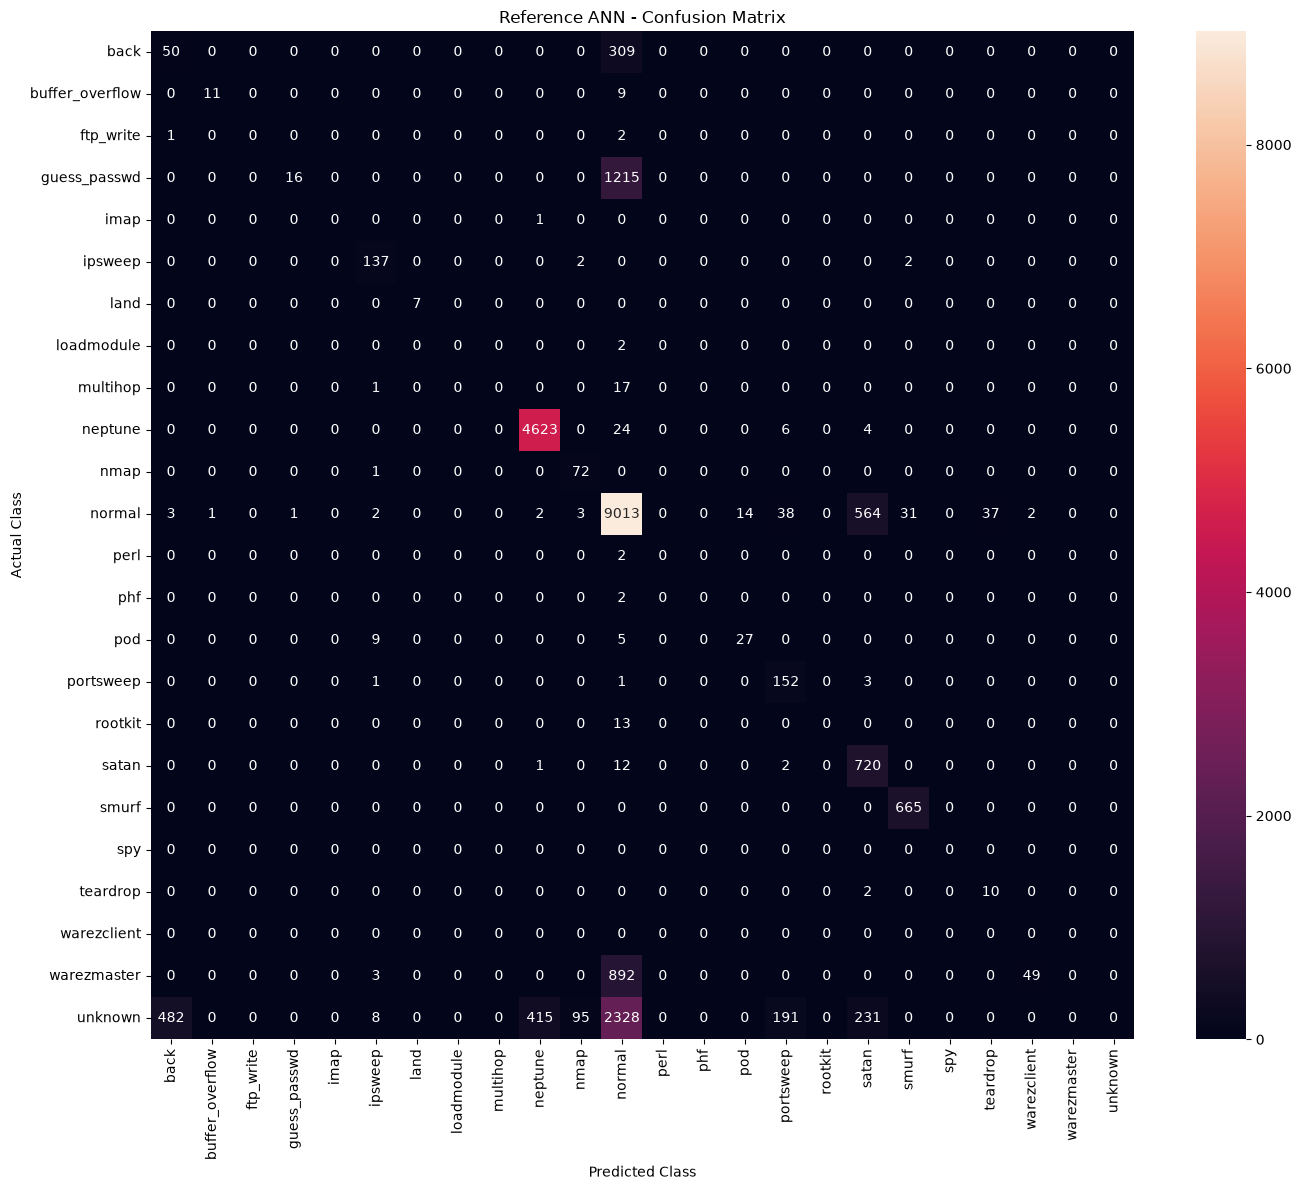

In [71]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test_true,
    y_test_pred,
    labels=range(24)
)

plt.figure(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=output_classes,
    yticklabels=output_classes
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Reference ANN - Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

## Extension Model — Random Forest

To extend the reference work, a Random Forest classifier is added as an additional machine learning model.

Random Forest is chosen because it is well suited for tabular datasets such as NSL-KDD and provides a fundamentally different approach from the neural network. While the reference model learns a neural representation of the input features, Random Forest combines multiple decision trees using ensemble learning.

The Random Forest is trained and evaluated using the same NSL-KDD training and testing data used for the reference ANN.

In [72]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_scaled,
    y_train_encoded
)

print("Random Forest training completed.")

Random Forest training completed.


In [73]:
# Random Forest predictions

rf_test_pred = rf_model.predict(X_test_scaled)

rf_test_accuracy = accuracy_score(
    y_test_24_indices,
    rf_test_pred
)

print("Random Forest test accuracy:", rf_test_accuracy)
print(
    "Random Forest test accuracy (%):",
    rf_test_accuracy * 100
)

Random Forest test accuracy: 0.7220546486870121
Random Forest test accuracy (%): 72.20546486870121


## Random Forest — Detailed Evaluation

The Random Forest is evaluated using precision, recall, and F1-score in addition to overall accuracy.

The same test labels used for evaluating the reference ANN are used here so that the two models can be compared fairly.

In [74]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test_24_indices,
        rf_test_pred,
        labels=range(24),
        target_names=output_classes,
        zero_division=0
    )
)

                 precision    recall  f1-score   support

           back       0.97      0.97      0.97       359
buffer_overflow       0.50      0.05      0.09        20
      ftp_write       0.00      0.00      0.00         3
   guess_passwd       0.00      0.00      0.00      1231
           imap       0.00      0.00      0.00         1
        ipsweep       0.75      0.98      0.85       141
           land       1.00      0.43      0.60         7
     loadmodule       0.00      0.00      0.00         2
       multihop       0.00      0.00      0.00        18
        neptune       0.97      1.00      0.98      4657
           nmap       0.59      1.00      0.74        73
         normal       0.63      0.97      0.77      9711
           perl       0.50      0.50      0.50         2
            phf       1.00      0.50      0.67         2
            pod       0.72      0.93      0.81        41
      portsweep       0.77      0.97      0.86       157
        rootkit       0.00    

In [75]:
# Random Forest Normal vs Abnormal accuracy

rf_y_test_binary = (
    y_test_24_indices == NORMAL_CLASS_INDEX
)

rf_y_pred_binary = (
    rf_test_pred == NORMAL_CLASS_INDEX
)

rf_normal_abnormal_accuracy = accuracy_score(
    rf_y_test_binary,
    rf_y_pred_binary
)

print(
    "Random Forest Normal/Abnormal accuracy:",
    rf_normal_abnormal_accuracy
)

print(
    "Random Forest Normal/Abnormal accuracy (%):",
    rf_normal_abnormal_accuracy * 100
)

Random Forest Normal/Abnormal accuracy: 0.7456973030518098
Random Forest Normal/Abnormal accuracy (%): 74.56973030518098


## Random Forest — Confusion Matrix

The confusion matrix shows how the Random Forest classifies each attack type and which classes are most frequently confused with one another.

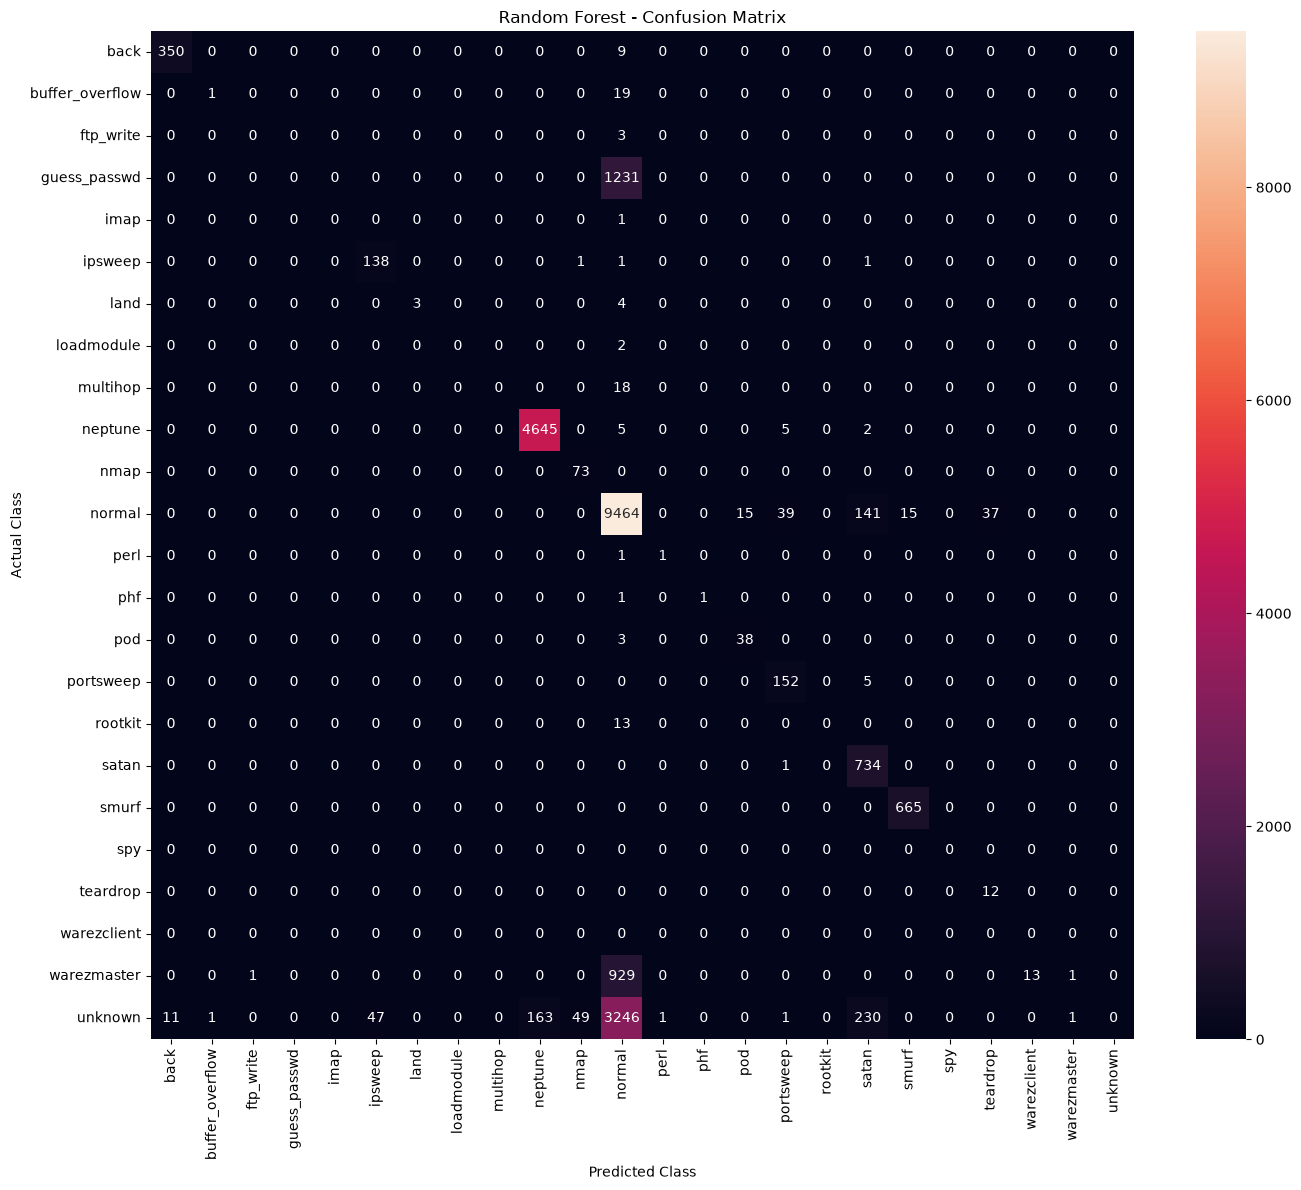

In [76]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

rf_cm = confusion_matrix(
    y_test_24_indices,
    rf_test_pred,
    labels=range(24)
)

plt.figure(figsize=(14, 12))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    xticklabels=output_classes,
    yticklabels=output_classes
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest - Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

## Fair Comparison on Known Attack Classes

The NSL-KDD test set contains attack types that do not occur in the training set.

The reference ANN explicitly includes an `unknown` output class, whereas the Random Forest is trained only on the 23 classes present in the training data.

To provide a fair comparison between the two models, their predictions are also evaluated on the subset of test samples whose classes were present during training.

In [77]:
# Identify test samples whose attack type was present in training

known_test_mask = test_df["attack_type"].isin(known_classes)

# True labels for known samples
known_true = y_test_24_indices[known_test_mask.values]

# Predictions from both models
ann_known_pred = y_test_pred[known_test_mask.values]
rf_known_pred = rf_test_pred[known_test_mask.values]

print("Known test samples:", len(known_true))

# Accuracy
ann_known_accuracy = accuracy_score(
    known_true,
    ann_known_pred
)

rf_known_accuracy = accuracy_score(
    known_true,
    rf_known_pred
)

print("\nANN known-class accuracy:",
      ann_known_accuracy * 100)

print("Random Forest known-class accuracy:",
      rf_known_accuracy * 100)

Known test samples: 18794

ANN known-class accuracy: 82.48909226348835
Random Forest known-class accuracy: 86.61274874960093


In [78]:
from sklearn.metrics import f1_score

ann_macro_f1 = f1_score(
    y_test_true,
    y_test_pred,
    average="macro",
    zero_division=0
)

ann_weighted_f1 = f1_score(
    y_test_true,
    y_test_pred,
    average="weighted",
    zero_division=0
)

rf_macro_f1 = f1_score(
    y_test_24_indices,
    rf_test_pred,
    average="macro",
    zero_division=0
)

rf_weighted_f1 = f1_score(
    y_test_24_indices,
    rf_test_pred,
    average="weighted",
    zero_division=0
)

print("ANN Macro F1:", ann_macro_f1)
print("ANN Weighted F1:", ann_weighted_f1)

print("\nRandom Forest Macro F1:", rf_macro_f1)
print("Random Forest Weighted F1:", rf_weighted_f1)

ANN Macro F1: 0.3566502365993653
ANN Weighted F1: 0.5930255397336787

Random Forest Macro F1: 0.4353906757756055
Random Forest Weighted F1: 0.6197323737268543


In [79]:
comparison = pd.DataFrame({
    "Model": [
        "Reference ANN",
        "Random Forest"
    ],
    "Test Accuracy (%)": [
        attack_accuracy * 100,
        rf_test_accuracy * 100
    ],
    "Normal/Abnormal Accuracy (%)": [
        normal_abnormal_accuracy * 100,
        rf_normal_abnormal_accuracy * 100
    ],
    "Macro F1": [
        ann_macro_f1,
        rf_macro_f1
    ],
    "Weighted F1": [
        ann_weighted_f1,
        rf_weighted_f1
    ],
    "Known-Class Accuracy (%)": [
        ann_known_accuracy * 100,
        rf_known_accuracy * 100
    ]
})

display(comparison.round(2))

,Model,Test Accuracy (%),Normal/Abnormal Accuracy (%),Macro F1,Weighted F1,Known-Class Accuracy (%)
0,Reference ANN,68.77,75.47,0.36,0.59,82.49
1,Random Forest,72.21,74.57,0.44,0.62,86.61


## Model Comparison

The reference ANN is compared with the additional Random Forest model using the same NSL-KDD test dataset and evaluation metrics.

| Model | Test Accuracy (%) | Normal/Abnormal Accuracy (%) | Macro F1 | Weighted F1 | Known-Class Accuracy (%) |
|---|---:|---:|---:|---:|---:|
| Reference ANN | 68.77 | 75.47 | 0.36 | 0.59 | 82.49 |
| Random Forest | 72.21 | 74.57 | 0.44 | 0.62 | 86.61 |

### Observation

- Random Forest achieves higher overall test accuracy than the reference ANN.
- Random Forest also performs better on the known attack classes.
- Random Forest has higher Macro F1 and Weighted F1 scores.
- ANN performs slightly better for the Normal vs Abnormal classification.
- Therefore, Random Forest provides better multi-class attack classification performance on this dataset.

## Single-Sample Inference – Network Intrusion Detection

In [80]:

# Single-Sample Inference

sample_index = 13
sample = X_test_scaled[sample_index:sample_index + 1]
actual_class = y_test.iloc[sample_index]

ann_probabilities = model.predict(sample, verbose=0)
ann_predicted_index = np.argmax(ann_probabilities, axis=1)[0]
ann_prediction = output_classes[ann_predicted_index]

rf_predicted_index = rf_model.predict(sample)[0]
rf_prediction = label_encoder.inverse_transform(
    [rf_predicted_index]
)[0]

print("SAMPLE INFERENCE")
print("-------------------------")
print("Sample index:", sample_index)
print("Number of features:", sample.shape[1])
print("Actual class:", actual_class)
print("ANN prediction:", ann_prediction)
print("Random Forest prediction:", rf_prediction)


SAMPLE INFERENCE
-------------------------
Sample index: 13
Number of features: 122
Actual class: neptune
ANN prediction: neptune
Random Forest prediction: neptune


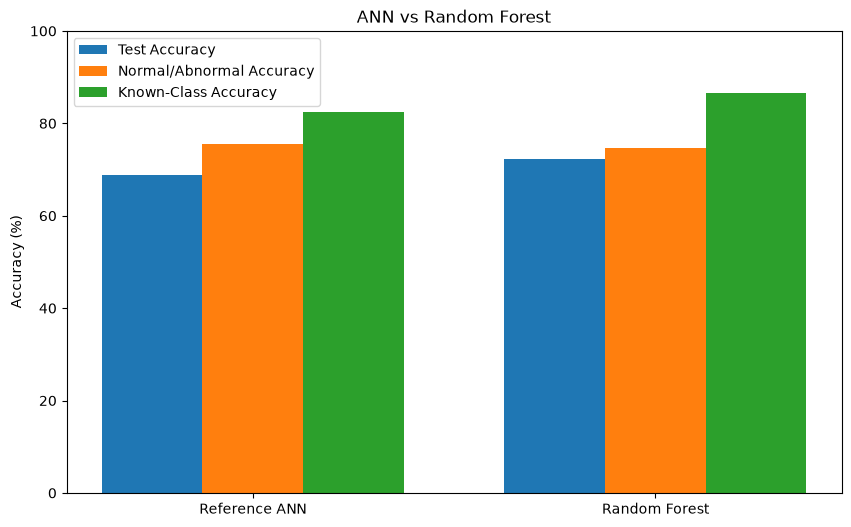

In [81]:
import matplotlib.pyplot as plt
import numpy as np

models = comparison["Model"]

test_accuracy = comparison["Test Accuracy (%)"]
normal_abnormal = comparison["Normal/Abnormal Accuracy (%)"]
known_class_accuracy = comparison["Known-Class Accuracy (%)"]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(10, 6))

plt.bar(x - width, test_accuracy, width, label="Test Accuracy")
plt.bar(x, normal_abnormal, width, label="Normal/Abnormal Accuracy")
plt.bar(x + width, known_class_accuracy, width, label="Known-Class Accuracy")

plt.ylabel("Accuracy (%)")
plt.title("ANN vs Random Forest")
plt.xticks(x, models)
plt.ylim(0, 100)
plt.legend()

plt.show()

## Conclusion

The results of the reference Artificial Neural Network were successfully reproduced using the NSL-KDD dataset. The implemented ANN used 122 input features, a 500-neuron sigmoid hidden layer, and a 24-neuron softmax output layer, following the architecture described in the reference paper.

The reproduced ANN achieved **68.77% test accuracy**, **75.47% Normal/Abnormal accuracy**, and **82.49% accuracy on known attack classes**. These results are reasonably close to the approximately **70% test accuracy** and **80% Normal/Abnormal accuracy** reported in the reference paper.

Random Forest was selected as the additional model because it provides a fundamentally different approach to classification and is well suited to structured tabular data. It achieved **72.21% test accuracy**, **0.44 macro F1-score**, **0.62 weighted F1-score**, and **86.61% accuracy on known attack classes**.

Therefore, Random Forest performed better than the reference ANN for multi-class attack classification, achieving higher test accuracy, macro F1-score, weighted F1-score, and known-class accuracy. The ANN performed slightly better for the Normal/Abnormal classification task, with **75.47%** accuracy compared with **74.57%** for Random Forest.

In [82]:
import os

os.makedirs("models", exist_ok=True)

# Save the trained ANN
model.save("models/reference_ann.keras")

# Save the trained Random Forest
import joblib

joblib.dump(
    rf_model,
    "models/random_forest.pkl"
)

print("Models saved successfully.")

Models saved successfully.
